In [1]:
import os

os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"

In [2]:
from pathlib import Path

%cd /content
!git lfs install

if not Path("/content/Project-phase-2").exists():
    !git clone https://github.com/CMU-18734-17731-2026-Fall/Project-phase-2.git

%cd /content/Project-phase-2
!git lfs pull

/content
Git LFS initialized.
/content/Project-phase-2


In [14]:
%pip install -r requirements.txt

In [15]:
%pip uninstall -y torchvision

In [3]:
!apt-get update -qq
!apt-get install -y git-lfs

%cd /content/Project-phase-2
!git lfs install
!git lfs pull

In [4]:
%cd /content/Project-phase-2

import subprocess
import sys

result = subprocess.run(
    [sys.executable, "scripts/verify_release.py"],
    capture_output=True,
    text=True,
)

print("Python:", sys.version)
print("STDOUT:\n", result.stdout)
print("STDERR:\n", result.stderr)
print("Exit code:", result.returncode)

/content/Project-phase-2
Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
STDOUT:
 Verified 8 release hashes
Verified data schemas, counts, and public train labels
Verified train, val, and final adapter configurations
Verified that hidden labels and organizer archives are absent
Verified clean notebook metadata and outputs
Verified that stale links and personal paths are absent
Phase 2 release verification: PASS

STDERR:
 
Exit code: 0


In [5]:
import os
import subprocess
import sys

env = os.environ.copy()
env["USE_TF"] = "0"
env["USE_FLAX"] = "0"

result = subprocess.run(
    [
        sys.executable,
        "-c",
        """
from transformers.models.bloom.modeling_bloom import BloomPreTrainedModel
from transformers.models.gpt2.modeling_gpt2 import GPT2LMHeadModel
from peft import PeftModel
print("Imports successful")
""",
    ],
    env=env,
    capture_output=True,
    text=True,
)

print(result.stdout)
print(result.stderr)

Imports successful




In [6]:
import json
import random
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from peft import PeftModel
from sklearn.metrics import roc_auc_score, roc_curve
from transformers import AutoModelForCausalLM, AutoTokenizer

SEED = 42
PHASE = "train"
BATCH_SIZE = 2
MAX_LENGTH = 512
MODEL_NAME = "gpt2_3_lora32_adamw_b8_lr2"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

ROOT = Path("/content/Project-phase-2")
DATA_DIR = ROOT / "data" / PHASE
ADAPTER_DIR = ROOT / "models" / PHASE / MODEL_NAME

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_dtype = torch.float16 if device.type == "cuda" else torch.float32

print("Phase:", PHASE)
print("Device:", device)

Phase: train
Device: cuda


In [7]:
def read_json(path):
    with Path(path).open("r", encoding="utf-8") as handle:
        return json.load(handle)


test_items = read_json(DATA_DIR / "test.json")

assert len(test_items) == 2000
assert all(isinstance(text, str) for text in test_items)

adapter_config = read_json(ADAPTER_DIR / "adapter_config.json")
base_model_name = adapter_config["base_model_name_or_path"]

tokenizer = AutoTokenizer.from_pretrained(
    ADAPTER_DIR,
    use_fast=True,
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "right"

print("Number of texts:", len(test_items))
print("Base model:", base_model_name)

Number of texts: 2000
Base model: gpt2


In [8]:
base_model = AutoModelForCausalLM.from_pretrained(
    base_model_name,
    torch_dtype=model_dtype,
)

model = PeftModel.from_pretrained(
    base_model,
    ADAPTER_DIR,
)

model.config.pad_token_id = tokenizer.pad_token_id
model.to(device)
model.eval()

print("Target model loaded.")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Target model loaded.


In [9]:
batch_texts = test_items[:2]

batch = tokenizer(
    batch_texts,
    return_tensors="pt",
    padding=True,
    truncation=True,
    max_length=MAX_LENGTH,
)

batch = {
    name: tensor.to(device)
    for name, tensor in batch.items()
}

print("Input shape:", batch["input_ids"].shape)
print("Valid token counts:", batch["attention_mask"].sum(dim=1).tolist())

Input shape: torch.Size([2, 201])
Valid token counts: [201, 152]


In [11]:
with torch.inference_mode():
    outputs = model(**batch, use_cache=False)

    shift_logits = outputs.logits[:, :-1, :]
    shift_targets = batch["input_ids"][:, 1:]
    shift_mask = batch["attention_mask"][:, 1:].bool()

    target_losses = F.cross_entropy(
        shift_logits.float().reshape(-1, shift_logits.shape[-1]),
        shift_targets.reshape(-1),
        reduction="none",
    ).reshape(shift_targets.shape)

print("Loss shape:", target_losses.shape)
print("Valid targets:", shift_mask.sum(dim=1).tolist())

for i in range(len(batch_texts)):
    valid_losses = target_losses[i][shift_mask[i]]
    print(f"Text {i}: target mean loss = {valid_losses.mean().item():.4f}")

del outputs, shift_logits

Loss shape: torch.Size([2, 200])
Valid targets: [200, 151]
Text 0: target mean loss = 2.4121
Text 1: target mean loss = 3.9171


In [13]:
with torch.inference_mode():
    with model.disable_adapter():
        outputs = model(**batch, use_cache=False)

    shift_logits = outputs.logits[:, :-1, :]

    base_losses = F.cross_entropy(
        shift_logits.float().reshape(-1, shift_logits.shape[-1]),
        shift_targets.reshape(-1),
        reduction="none",
    ).reshape(shift_targets.shape)

token_improvements = base_losses - target_losses

valid_improvements = [
    differences[mask].detach().cpu()
    for differences, mask in zip(token_improvements, shift_mask)
]

for i, differences in enumerate(valid_improvements):
    assert differences.numel() > 0
    assert torch.isfinite(differences).all()

    print(
        f"Text {i} | "
        f"Base loss: {base_losses[i][shift_mask[i]].mean().item():.4f} | "
        f"Target loss: {target_losses[i][shift_mask[i]].mean().item():.4f} | "
        f"Mean improvement: {differences.mean().item():.4f}"
    )

del outputs, shift_logits

Text 0 | Base loss: 2.7446 | Target loss: 2.4121 | Mean improvement: 0.3326
Text 1 | Base loss: 4.3945 | Target loss: 3.9171 | Mean improvement: 0.4774


In [14]:
# Cell 10 — Sliding-window votes for our two example texts
# Each window votes for membership if its mean improvement is positive.
# Average votes within each window size, then average across sizes.

WINDOW_SIZES = (1, 2, 4, 8, 16, 32, 64, 128)


def sliding_window_score(differences, window_sizes=WINDOW_SIZES):
    assert differences.ndim == 1
    assert differences.numel() > 0
    assert torch.isfinite(differences).all()

    votes_by_size = {}

    for width in window_sizes:
        if width > differences.numel():
            continue

        windows = differences.unfold(
            dimension=0,
            size=width,
            step=1,
        )
        window_means = windows.mean(dim=1)
        vote_fraction = (window_means > 0).float().mean().item()

        votes_by_size[width] = vote_fraction

    if not votes_by_size:
        raise ValueError("No window size fits this text.")

    score = float(np.mean(list(votes_by_size.values())))
    return score, votes_by_size


for i, differences in enumerate(valid_improvements):
    score, votes = sliding_window_score(differences)

    print(f"\nText {i} | Sliding-window score: {score:.4f}")
    for width, fraction in votes.items():
        print(f"  Window {width:3d} | Positive votes: {fraction:.4f}")


Text 0 | Sliding-window score: 0.8744
  Window   1 | Positive votes: 0.6400
  Window   2 | Positive votes: 0.7136
  Window   4 | Positive votes: 0.8274
  Window   8 | Positive votes: 0.9016
  Window  16 | Positive votes: 0.9189
  Window  32 | Positive votes: 0.9941
  Window  64 | Positive votes: 1.0000
  Window 128 | Positive votes: 1.0000

Text 1 | Sliding-window score: 0.8531
  Window   1 | Positive votes: 0.6821
  Window   2 | Positive votes: 0.7000
  Window   4 | Positive votes: 0.7703
  Window   8 | Positive votes: 0.8403
  Window  16 | Positive votes: 0.8824
  Window  32 | Positive votes: 0.9500
  Window  64 | Positive votes: 1.0000
  Window 128 | Positive votes: 1.0000


In [15]:
# Cell 11 — Collect token losses for all 2,000 texts.
# Cache both models' losses so we can try window sizes without rerunning inference.

from tqdm.auto import tqdm


@torch.inference_mode()
def collect_token_losses(
    model, tokenizer, texts, device, batch_size=2, max_length=512
):
    model.eval()
    cached_target_losses = []
    cached_base_losses = []

    for start in tqdm(range(0, len(texts), batch_size)):
        batch = tokenizer(
            texts[start:start + batch_size],
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_length,
        )
        batch = {name: tensor.to(device) for name, tensor in batch.items()}

        targets = batch["input_ids"][:, 1:]
        mask = batch["attention_mask"][:, 1:].bool()

        if not mask.any(dim=1).all():
            raise ValueError(f"Text without valid next-token targets in batch {start}")

        def get_losses():
            outputs = model(**batch, use_cache=False)
            logits = outputs.logits[:, :-1, :]

            losses = F.cross_entropy(
                logits.float().reshape(-1, logits.shape[-1]),
                targets.reshape(-1),
                reduction="none",
            ).reshape(targets.shape)

            return losses

        target_losses = get_losses()

        with model.disable_adapter():
            base_losses = get_losses()

        for target_row, base_row, valid_mask in zip(
            target_losses, base_losses, mask
        ):
            target_valid = target_row[valid_mask].float().cpu().numpy()
            base_valid = base_row[valid_mask].float().cpu().numpy()

            assert np.isfinite(target_valid).all()
            assert np.isfinite(base_valid).all()

            cached_target_losses.append(target_valid)
            cached_base_losses.append(base_valid)

    return cached_target_losses, cached_base_losses


cached_target_losses, cached_base_losses = collect_token_losses(
    model=model,
    tokenizer=tokenizer,
    texts=test_items,
    device=device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH,
)

assert len(cached_target_losses) == len(test_items)
assert len(cached_base_losses) == len(test_items)

print(f"Cached losses for {len(cached_target_losses)} texts.")

  0%|          | 0/1000 [00:00<?, ?it/s]

Cached losses for 2000 texts.


Average loss     | AUC=0.5427 | TPR@FPR<1%=0.0030 | TPR@FPR<5%=0.0560
Reference loss   | AUC=0.5821 | TPR@FPR<1%=0.0170 | TPR@FPR<5%=0.0520
Sliding windows  | AUC=0.7369 | TPR@FPR<1%=0.0260 | TPR@FPR<5%=0.1520


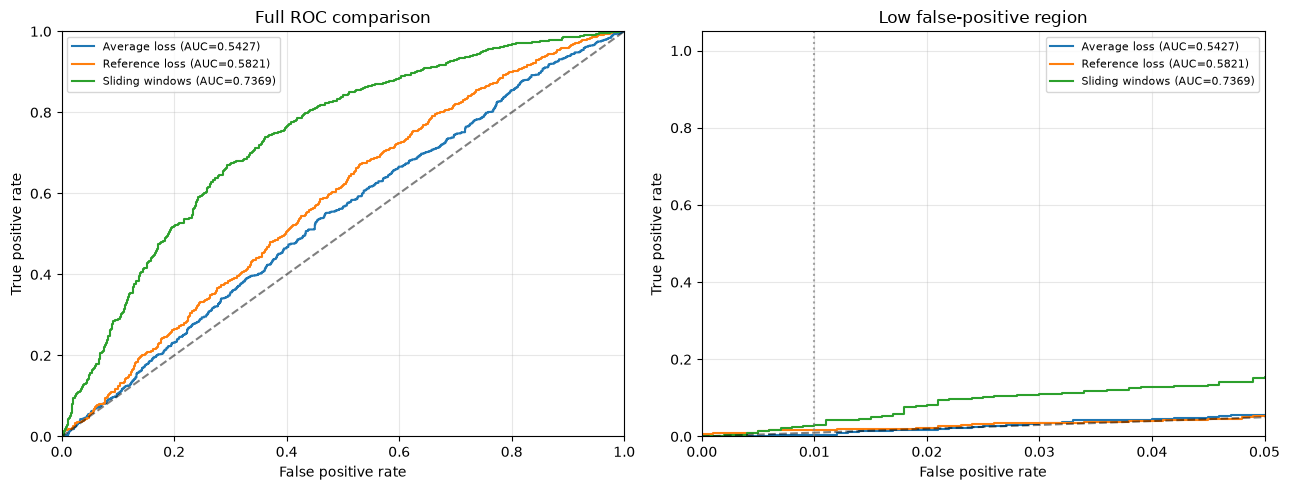

In [16]:
# Cell 12 — Score all texts and compare with two baselines

loss_scores = np.array([
    -losses.mean() for losses in cached_target_losses
])

reference_scores = np.array([
    (base - target).mean()
    for base, target in zip(cached_base_losses, cached_target_losses)
])

window_scores = np.array([
    sliding_window_score(torch.from_numpy(base - target))[0]
    for base, target in zip(cached_base_losses, cached_target_losses)
])

assert PHASE == "train", "Local evaluation requires public train labels."
labels = np.asarray(read_json(DATA_DIR / "test_label.json"), dtype=np.int64)

attack_scores = {
    "Average loss": loss_scores,
    "Reference loss": reference_scores,
    "Sliding windows": window_scores,
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, scores in attack_scores.items():
    assert scores.shape == labels.shape
    assert np.isfinite(scores).all()

    fpr, tpr, _ = roc_curve(labels, scores)
    auc = roc_auc_score(labels, scores)
    tpr_1 = np.max(tpr[fpr < 0.01])
    tpr_5 = np.max(tpr[fpr < 0.05])

    print(
        f"{name:16s} | AUC={auc:.4f} | "
        f"TPR@FPR<1%={tpr_1:.4f} | TPR@FPR<5%={tpr_5:.4f}"
    )

    for ax in axes:
        ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.4f})")

for ax in axes:
    ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_title("Full ROC comparison")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)

axes[1].set_title("Low false-positive region")
axes[1].set_xlim(0, 0.05)
axes[1].set_ylim(bottom=0)
axes[1].axvline(0.01, color="gray", linestyle=":", alpha=0.7)

plt.tight_layout()
plt.show()

In [17]:
# Cell 13 — Compare individual window sizes on the development target.
# For texts shorter than a window, use the entire valid sequence.
# These are exploratory development results, not held-out estimates.

cached_differences = [
    torch.from_numpy(base - target)
    for base, target in zip(cached_base_losses, cached_target_losses)
]

scores_by_window = {}

for width in WINDOW_SIZES:
    scores = []

    for differences in cached_differences:
        effective_width = min(width, differences.numel())

        window_means = differences.unfold(
            dimension=0,
            size=effective_width,
            step=1,
        ).mean(dim=1)

        scores.append((window_means > 0).float().mean().item())

    scores = np.asarray(scores)
    scores_by_window[width] = scores

    fpr, tpr, _ = roc_curve(labels, scores)

    print(
        f"Window={width:3d} | "
        f"AUC={roc_auc_score(labels, scores):.4f} | "
        f"TPR@FPR<1%={np.max(tpr[fpr < 0.01]):.4f} | "
        f"TPR@FPR<5%={np.max(tpr[fpr < 0.05]):.4f} | "
        f"Unique scores={np.unique(scores).size}"
    )

Window=  1 | AUC=0.7029 | TPR@FPR<1%=0.0180 | TPR@FPR<5%=0.1330 | Unique scores=1316
Window=  2 | AUC=0.7191 | TPR@FPR<1%=0.0160 | TPR@FPR<5%=0.1200 | Unique scores=1393
Window=  4 | AUC=0.7226 | TPR@FPR<1%=0.0270 | TPR@FPR<5%=0.1260 | Unique scores=1424
Window=  8 | AUC=0.7183 | TPR@FPR<1%=0.0000 | TPR@FPR<5%=0.1030 | Unique scores=1324
Window= 16 | AUC=0.6886 | TPR@FPR<1%=0.0000 | TPR@FPR<5%=0.0000 | Unique scores=1030
Window= 32 | AUC=0.6046 | TPR@FPR<1%=0.0000 | TPR@FPR<5%=0.0000 | Unique scores=493
Window= 64 | AUC=0.5296 | TPR@FPR<1%=0.0000 | TPR@FPR<5%=0.0000 | Unique scores=97
Window=128 | AUC=0.5020 | TPR@FPR<1%=0.0000 | TPR@FPR<5%=0.0000 | Unique scores=5


In [18]:
# Cell 14 — Diagnose tied maximum scores and saturation

for width, scores in scores_by_window.items():
    members = scores[labels == 1]
    nonmembers = scores[labels == 0]

    maximum = scores.max()
    top_members = np.sum(members == maximum)
    top_nonmembers = np.sum(nonmembers == maximum)

    print(
        f"Window={width:3d} | "
        f"Member mean={members.mean():.4f} | "
        f"Nonmember mean={nonmembers.mean():.4f} | "
        f"Score=1: {np.mean(scores == 1):.1%} | "
        f"At maximum: {top_members} members, "
        f"{top_nonmembers} nonmembers"
    )

Window=  1 | Member mean=0.7136 | Nonmember mean=0.6709 | Score=1: 0.0% | At maximum: 0 members, 1 nonmembers
Window=  2 | Member mean=0.7444 | Nonmember mean=0.6872 | Score=1: 0.1% | At maximum: 0 members, 1 nonmembers
Window=  4 | Member mean=0.8103 | Nonmember mean=0.7415 | Score=1: 0.6% | At maximum: 8 members, 4 nonmembers
Window=  8 | Member mean=0.8924 | Nonmember mean=0.8208 | Score=1: 5.4% | At maximum: 72 members, 36 nonmembers
Window= 16 | Member mean=0.9597 | Nonmember mean=0.9025 | Score=1: 30.8% | At maximum: 399 members, 217 nonmembers
Window= 32 | Member mean=0.9895 | Nonmember mean=0.9655 | Score=1: 72.2% | At maximum: 818 members, 627 nonmembers
Window= 64 | Member mean=0.9987 | Nonmember mean=0.9916 | Score=1: 95.2% | At maximum: 981 members, 922 nonmembers
Window=128 | Member mean=1.0000 | Nonmember mean=0.9986 | Score=1: 99.8% | At maximum: 1000 members, 996 nonmembers


In [19]:
# Cell 15 — Compare a few small-window ensembles
# Exploratory results on the same development labels.

window_groups = {
    "Windows 1,2,4": (1, 2, 4),
    "Windows 2,4": (2, 4),
    "Windows 1,2,4,8": (1, 2, 4, 8),
}

ensemble_scores = {}

for name, widths in window_groups.items():
    scores = np.mean(
        np.stack([scores_by_window[w] for w in widths]),
        axis=0,
    )
    ensemble_scores[name] = scores

    fpr, tpr, _ = roc_curve(labels, scores)

    print(
        f"{name:18s} | "
        f"AUC={roc_auc_score(labels, scores):.4f} | "
        f"TPR@FPR<1%={np.max(tpr[fpr < 0.01]):.4f} | "
        f"TPR@FPR<5%={np.max(tpr[fpr < 0.05]):.4f}"
    )

Windows 1,2,4      | AUC=0.7262 | TPR@FPR<1%=0.0230 | TPR@FPR<5%=0.1500
Windows 2,4        | AUC=0.7257 | TPR@FPR<1%=0.0270 | TPR@FPR<5%=0.1530
Windows 1,2,4,8    | AUC=0.7303 | TPR@FPR<1%=0.0230 | TPR@FPR<5%=0.1510


In [20]:
# Cell 16 — Soft sliding-window votes
# Fixed temperature for this experiment; smaller values approach hard voting.
# Skip windows longer than the text, matching the original ensemble.

TEMPERATURE = 0.5


def soft_window_score(differences, temperature=TEMPERATURE):
    votes = []

    for width in WINDOW_SIZES:
        if width > differences.numel():
            continue

        window_means = differences.unfold(
            dimension=0,
            size=width,
            step=1,
        ).mean(dim=1)

        # Float64 reduces numerical saturation of the sigmoid.
        soft_votes = torch.sigmoid(window_means.double() / temperature)
        votes.append(soft_votes.mean().item())

    return float(np.mean(votes))


soft_window_scores = np.asarray([
    soft_window_score(differences)
    for differences in cached_differences
])

for name, scores in {
    "Hard windows": window_scores,
    "Soft windows": soft_window_scores,
    "Reference loss": reference_scores,
}.items():
    assert np.isfinite(scores).all()
    fpr, tpr, _ = roc_curve(labels, scores)

    print(
        f"{name:16s} | "
        f"AUC={roc_auc_score(labels, scores):.4f} | "
        f"TPR@FPR<1%={np.max(tpr[fpr < 0.01]):.4f} | "
        f"TPR@FPR<5%={np.max(tpr[fpr < 0.05]):.4f} | "
        f"Unique scores={np.unique(scores).size}"
    )

Hard windows     | AUC=0.7369 | TPR@FPR<1%=0.0260 | TPR@FPR<5%=0.1520 | Unique scores=2000
Soft windows     | AUC=0.6243 | TPR@FPR<1%=0.0160 | TPR@FPR<5%=0.0580 | Unique scores=2000
Reference loss   | AUC=0.5821 | TPR@FPR<1%=0.0170 | TPR@FPR<5%=0.0520 | Unique scores=2000


In [21]:
# Cell 17 — Inspect shadow-data and training options

import subprocess
import sys

for script in [
    "data/prepare_finetuning_data.py",
    "ft_llm/train_shadow_model.py",
]:
    result = subprocess.run(
        [sys.executable, str(ROOT / script), "--help"],
        capture_output=True,
        text=True,
    )

    print(f"\n{script}\n")
    print(result.stdout)

    if result.returncode != 0:
        print(result.stderr)


data/prepare_finetuning_data.py

usage: prepare_finetuning_data.py [-h] [--seed SEED]
                                  [--num-samples NUM_SAMPLES]
                                  [--min-tokens MIN_TOKENS]
                                  --output-dir OUTPUT_DIR
                                  [--model-name MODEL_NAME]

options:
  -h, --help            show this help message and exit
  --seed SEED
  --num-samples NUM_SAMPLES
  --min-tokens MIN_TOKENS
  --output-dir OUTPUT_DIR
  --model-name MODEL_NAME


ft_llm/train_shadow_model.py

usage: train_shadow_model.py [-h] --data-dir DATA_DIR
                             [--train-file TRAIN_FILE]
                             [--model-name MODEL_NAME] --outdir OUTDIR
                             [--block-size BLOCK_SIZE] [--epochs EPOCHS]
                             [--batch-size BATCH_SIZE]
                             [--gradient-accumulation-steps GRADIENT_ACCUMULATION_STEPS]
                             [--lr LR] [--weight-decay WEI

In [22]:
# Cell 18 — Generate shadow-training candidates.
# Do not train on this unfiltered candidate pool.

import os
import subprocess
import sys

SHADOW_SEED = 1001
CANDIDATE_DIR = ROOT / "data" / f"shadow_candidates_{SHADOW_SEED}"
SHADOW_DATA_DIR = ROOT / "data" / f"shadow_{SHADOW_SEED}"
SHADOW_MODEL_DIR = ROOT / "models" / f"shadow_{SHADOW_SEED}"

# Match the number of examples in the public target's fine-tuning set.
public_training_records = read_json(
    ROOT / "data" / "train" / "train_finetune.json"
)
SHADOW_TRAIN_SIZE = len(public_training_records)
CANDIDATE_COUNT = 2 * SHADOW_TRAIN_SIZE

env = os.environ.copy()
env["USE_TF"] = "0"
env["USE_FLAX"] = "0"

command = [
    sys.executable,
    str(ROOT / "data" / "prepare_finetuning_data.py"),
    "--seed", str(SHADOW_SEED),
    "--num-samples", str(CANDIDATE_COUNT),
    "--min-tokens", "25",
    "--model-name", base_model_name,
    "--output-dir", str(CANDIDATE_DIR),
]

# Stream output so download or preparation failures remain visible.
with subprocess.Popen(
    command,
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
) as process:
    for line in process.stdout:
        print(line, end="")

    return_code = process.wait()

if return_code != 0:
    raise RuntimeError(f"Candidate generation failed: exit code {return_code}")

candidate_records = read_json(CANDIDATE_DIR / "train_finetune.json")

print("\nRequired training examples:", SHADOW_TRAIN_SIZE)
print("Generated candidates:", len(candidate_records))









Wrote 20000 examples to /content/Project-phase-2/data/shadow_candidates_1001/train_finetune.json
Sampling seed: 1001

Required training examples: 10000
Generated candidates: 20000


In [23]:
# Cell 19 — Exclude development/validation examples and duplicate candidates.
# Check both whitespace-normalized text and the first MAX_LENGTH token IDs.
# This checks exact matches, not all possible near-duplicates or shared passages.

import hashlib


def extract_text(record):
    return record if isinstance(record, str) else record["text"]


def normalize_text(text):
    return " ".join(text.split())


def prefix_keys(texts):
    keys = []

    for start in range(0, len(texts), 256):
        encoded = tokenizer(
            texts[start:start + 256],
            add_special_tokens=False,
            truncation=True,
            max_length=MAX_LENGTH,
            padding=False,
        )

        for ids in encoded["input_ids"]:
            token_bytes = np.asarray(ids, dtype="<i4").tobytes()
            keys.append(hashlib.sha256(token_bytes).hexdigest())

    return keys


# Use evaluation text only; membership labels are not used here.
evaluation_texts = []

for phase in ("train", "val"):
    evaluation_texts.extend(
        read_json(ROOT / "data" / phase / "test.json")
    )

blocked_texts = {normalize_text(text) for text in evaluation_texts}

# Include raw and whitespace-normalized versions in the prefix check.
blocked_prefixes = set(prefix_keys(evaluation_texts))
blocked_prefixes.update(prefix_keys(sorted(blocked_texts)))

candidate_texts = [
    normalize_text(extract_text(record))
    for record in candidate_records
]
candidate_prefixes = prefix_keys(candidate_texts)

selected_texts = []
seen_texts = set()
seen_prefixes = set()
excluded_overlap = 0
excluded_duplicate = 0

for text, key in zip(candidate_texts, candidate_prefixes):
    if text in blocked_texts or key in blocked_prefixes:
        excluded_overlap += 1
        continue

    if text in seen_texts or key in seen_prefixes:
        excluded_duplicate += 1
        continue

    seen_texts.add(text)
    seen_prefixes.add(key)
    selected_texts.append(text)

if len(selected_texts) < SHADOW_TRAIN_SIZE:
    raise ValueError(
        f"Only {len(selected_texts)} eligible candidates remain; "
        f"need {SHADOW_TRAIN_SIZE}. Generate a larger candidate pool."
    )

# Preserve the sampler's seeded order.
shadow_texts = selected_texts[:SHADOW_TRAIN_SIZE]

assert not set(shadow_texts).intersection(blocked_texts)
assert not set(prefix_keys(shadow_texts)).intersection(blocked_prefixes)

SHADOW_DATA_DIR.mkdir(parents=True, exist_ok=True)

with (SHADOW_DATA_DIR / "train_finetune.json").open(
    "w", encoding="utf-8"
) as handle:
    json.dump(
        [{"text": text} for text in shadow_texts],
        handle,
        ensure_ascii=False,
        indent=2,
    )

print("Excluded evaluation overlaps:", excluded_overlap)
print("Excluded duplicate candidates:", excluded_duplicate)
print("Saved shadow-training examples:", len(shadow_texts))
print("Data directory:", SHADOW_DATA_DIR)

Excluded evaluation overlaps: 119
Excluded duplicate candidates: 16
Saved shadow-training examples: 10000
Data directory: /content/Project-phase-2/data/shadow_1001


In [24]:
# Cell 20 — Train the shadow reference model.
# Batch size 2 × accumulation 4 = effective batch size 8.
# This cell takes substantially longer than scoring.

import gc
import os
import subprocess
import sys

assert torch.cuda.is_available(), "Select a GPU runtime before training."

# Save cached losses before the long training run.
# These files remain on the Colab runtime disk, not persistent Drive storage.
CACHE_DIR = ROOT / "cache"
CACHE_DIR.mkdir(exist_ok=True)

lengths = np.asarray([len(x) for x in cached_target_losses], dtype=np.int64)

np.savez_compressed(
    CACHE_DIR / "train_base_target_losses.npz",
    lengths=lengths,
    target_losses=np.concatenate(cached_target_losses),
    base_losses=np.concatenate(cached_base_losses),
    max_length=MAX_LENGTH,
)

# Free GPU memory occupied by the development target.
# Move it back to the GPU later when needed.
model.to("cpu")
gc.collect()
torch.cuda.empty_cache()

if SHADOW_MODEL_DIR.exists() and any(SHADOW_MODEL_DIR.iterdir()):
    raise RuntimeError(
        f"Output directory is not empty: {SHADOW_MODEL_DIR}. "
        "Inspect it before restarting training."
    )

env = os.environ.copy()
env["USE_TF"] = "0"
env["USE_FLAX"] = "0"
env["TOKENIZERS_PARALLELISM"] = "false"

target_modules = adapter_config["target_modules"]
assert isinstance(target_modules, list)

command = [
    sys.executable,
    str(ROOT / "ft_llm" / "train_shadow_model.py"),
    "--data-dir", str(SHADOW_DATA_DIR),
    "--outdir", str(SHADOW_MODEL_DIR),
    "--model-name", base_model_name,
    "--epochs", "3",
    "--batch-size", "2",
    "--gradient-accumulation-steps", "4",
    "--block-size", "512",
    "--lr", "2e-4",
    "--weight-decay", "0.01",
    "--seed", "42",
    "--lora-r", str(adapter_config["r"]),
    "--lora-alpha", str(adapter_config["lora_alpha"]),
    "--lora-dropout", str(adapter_config["lora_dropout"]),
    "--target-modules", ",".join(target_modules),
    "--precision", "auto",
    "--gradient-checkpointing",
]

print("GPU:", torch.cuda.get_device_name(0))
print("Training examples:", len(shadow_texts))
print("Effective batch size: 8")
print("Output:", SHADOW_MODEL_DIR)

with subprocess.Popen(
    command,
    cwd=ROOT,
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
) as process:
    for line in process.stdout:
        print(line, end="")

    return_code = process.wait()

if return_code != 0:
    raise RuntimeError(f"Shadow training failed: exit code {return_code}")

assert (SHADOW_MODEL_DIR / "adapter_model.safetensors").is_file()
print("\nShadow model saved successfully.")

[... log truncated ...]
7096798032983, 'epoch': 0.88}
{'loss': 3.4576, 'grad_norm': 0.6073790192604065, 'learning_rate': 0.00015913435101584398, 'epoch': 0.96}
{'loss': 3.4556, 'grad_norm': 0.5450210571289062, 'learning_rate': 0.00015195679056782227, 'epoch': 1.04}
{'loss': 3.4726, 'grad_norm': 0.5277006030082703, 'learning_rate': 0.00014439180711045394, 'epoch': 1.12}
{'loss': 3.4306, 'grad_norm': 0.5568138360977173, 'learning_rate': 0.0001364958099912887, 'epoch': 1.2}
{'loss': 3.4134, 'grad_norm': 0.5555724501609802, 'learning_rate': 0.0001283276768071194, 'epoch': 1.28}
{'loss': 3.4482, 'grad_norm': 0.5203821659088135, 'learning_rate': 0.00011994831437502173, 'epoch': 1.36}
{'loss': 3.4413, 'grad_norm': 0.6706722378730774, 'learning_rate': 0.00011142020457223194, 'epoch': 1.44}
{'loss': 3.4378, 'grad_norm': 0.5596128106117249, 'learning_rate': 0.00010280693843137019, 'epoch': 1.52}
{'loss': 3.4199, 'grad_norm': 0.5518427491188049, 'learning_rate': 9.417274196509289e-05, 'epoch': 1.

In [25]:
# Cell 21 — Load the shadow model and cache its token losses.
# Compare against the target losses already cached in Cell 11.

shadow_base = AutoModelForCausalLM.from_pretrained(
    base_model_name,
    torch_dtype=model_dtype,
)

shadow_model = PeftModel.from_pretrained(
    shadow_base,
    SHADOW_MODEL_DIR,
)

shadow_model.config.pad_token_id = tokenizer.pad_token_id
shadow_model.to(device)
shadow_model.eval()


@torch.inference_mode()
def collect_shadow_losses(
    shadow_model, tokenizer, texts, device, batch_size, max_length
):
    cached_losses = []

    for start in tqdm(range(0, len(texts), batch_size)):
        batch = tokenizer(
            texts[start:start + batch_size],
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_length,
        )
        batch = {name: tensor.to(device) for name, tensor in batch.items()}

        targets = batch["input_ids"][:, 1:]
        mask = batch["attention_mask"][:, 1:].bool()

        outputs = shadow_model(**batch, use_cache=False)
        logits = outputs.logits[:, :-1, :]

        losses = F.cross_entropy(
            logits.float().reshape(-1, logits.shape[-1]),
            targets.reshape(-1),
            reduction="none",
        ).reshape(targets.shape)

        for row, valid_mask in zip(losses, mask):
            valid_losses = row[valid_mask].float().cpu().numpy()

            assert valid_losses.size > 0
            assert np.isfinite(valid_losses).all()
            cached_losses.append(valid_losses)

        del outputs, logits, losses

    return cached_losses


cached_shadow_losses = collect_shadow_losses(
    shadow_model=shadow_model,
    tokenizer=tokenizer,
    texts=test_items,
    device=device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH,
)

assert len(cached_shadow_losses) == len(cached_target_losses)

for shadow, target in zip(cached_shadow_losses, cached_target_losses):
    assert shadow.shape == target.shape

np.savez_compressed(
    CACHE_DIR / f"train_shadow_{SHADOW_SEED}_losses.npz",
    lengths=np.asarray([len(x) for x in cached_shadow_losses]),
    shadow_losses=np.concatenate(cached_shadow_losses),
    max_length=MAX_LENGTH,
)

print(f"Cached shadow losses for {len(cached_shadow_losses)} texts.")

  0%|          | 0/1000 [00:00<?, ?it/s]

Cached shadow losses for 2000 texts.


Average loss       | AUC=0.5427 | TPR@FPR<1%=0.0030 | TPR@FPR<5%=0.0560 | Unique scores=2000
Base reference     | AUC=0.5821 | TPR@FPR<1%=0.0170 | TPR@FPR<5%=0.0520 | Unique scores=2000
Base windows       | AUC=0.7369 | TPR@FPR<1%=0.0260 | TPR@FPR<5%=0.1520 | Unique scores=2000
Shadow reference   | AUC=0.9294 | TPR@FPR<1%=0.1920 | TPR@FPR<5%=0.6640 | Unique scores=2000
Shadow windows     | AUC=0.9274 | TPR@FPR<1%=0.3640 | TPR@FPR<5%=0.6430 | Unique scores=2000


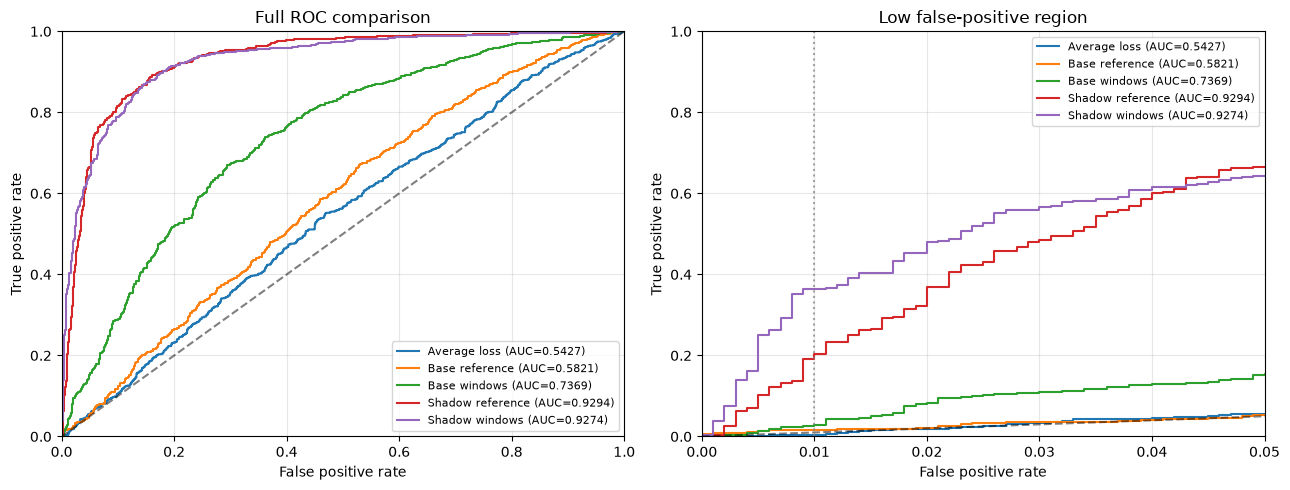

In [26]:
# Cell 22 — Evaluate shadow-reference attacks.
# Keep the original hard-window scoring rule unchanged.

shadow_reference_scores = np.asarray([
    (shadow - target).mean()
    for shadow, target in zip(cached_shadow_losses, cached_target_losses)
])

shadow_window_scores = np.asarray([
    sliding_window_score(torch.from_numpy(shadow - target))[0]
    for shadow, target in zip(cached_shadow_losses, cached_target_losses)
])

comparison_scores = {
    "Average loss": loss_scores,
    "Base reference": reference_scores,
    "Base windows": window_scores,
    "Shadow reference": shadow_reference_scores,
    "Shadow windows": shadow_window_scores,
}

assert PHASE == "train"

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, scores in comparison_scores.items():
    assert scores.shape == labels.shape
    assert np.isfinite(scores).all()

    fpr, tpr, _ = roc_curve(labels, scores)
    auc = roc_auc_score(labels, scores)
    tpr_1 = np.max(tpr[fpr < 0.01])
    tpr_5 = np.max(tpr[fpr < 0.05])

    print(
        f"{name:18s} | AUC={auc:.4f} | "
        f"TPR@FPR<1%={tpr_1:.4f} | "
        f"TPR@FPR<5%={tpr_5:.4f} | "
        f"Unique scores={np.unique(scores).size}"
    )

    for ax in axes:
        ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.4f})")

for ax in axes:
    ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_title("Full ROC comparison")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)

axes[1].set_title("Low false-positive region")
axes[1].set_xlim(0, 0.05)
axes[1].set_ylim(0, 1)
axes[1].axvline(0.01, color="gray", linestyle=":", alpha=0.7)

plt.tight_layout()
plt.show()

In [27]:
# Cell 23 — Back up the shadow adapter, training data, and cached losses

import shutil
from google.colab import files

backup_dir = ROOT / f"phase2_backup_{SHADOW_SEED}"
backup_dir.mkdir(exist_ok=True)

shutil.copytree(
    SHADOW_MODEL_DIR,
    backup_dir / "shadow_adapter",
    dirs_exist_ok=True,
)
shutil.copytree(
    SHADOW_DATA_DIR,
    backup_dir / "shadow_data",
    dirs_exist_ok=True,
)
shutil.copytree(
    CACHE_DIR,
    backup_dir / "cache",
    dirs_exist_ok=True,
)

np.savez_compressed(
    backup_dir / "development_scores.npz",
    labels=labels,
    **{
        name.replace(" ", "_"): scores
        for name, scores in comparison_scores.items()
    },
)

archive = shutil.make_archive(
    str(ROOT / f"phase2_backup_{SHADOW_SEED}"),
    "zip",
    root_dir=backup_dir,
)

files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
# Cell 24 — Check which window sizes work with the shadow reference.
# Exploratory development results; no additional model inference.

shadow_differences = [
    torch.from_numpy(shadow - target)
    for shadow, target in zip(cached_shadow_losses, cached_target_losses)
]

shadow_scores_by_window = {}

for width in WINDOW_SIZES:
    scores = []

    for differences in shadow_differences:
        # For this single-size comparison, use the full sequence
        # when the requested window is longer than the text.
        effective_width = min(width, differences.numel())

        window_means = differences.unfold(
            dimension=0,
            size=effective_width,
            step=1,
        ).mean(dim=1)

        scores.append((window_means > 0).float().mean().item())

    scores = np.asarray(scores)
    shadow_scores_by_window[width] = scores

    fpr, tpr, _ = roc_curve(labels, scores)

    print(
        f"Window={width:3d} | "
        f"AUC={roc_auc_score(labels, scores):.4f} | "
        f"TPR@FPR<1%={np.max(tpr[fpr < 0.01]):.4f} | "
        f"TPR@FPR<5%={np.max(tpr[fpr < 0.05]):.4f} | "
        f"Score=1: {np.mean(scores == 1):.1%}"
    )

print(
    f"\nOriginal shadow-window ensemble | "
    f"AUC={roc_auc_score(labels, shadow_window_scores):.4f}"
)
fpr, tpr, _ = roc_curve(labels, shadow_window_scores)
print(f"TPR@FPR<1%={np.max(tpr[fpr < 0.01]):.4f}")

Window=  1 | AUC=0.8740 | TPR@FPR<1%=0.1120 | TPR@FPR<5%=0.4010 | Score=1: 0.0%
Window=  2 | AUC=0.9035 | TPR@FPR<1%=0.1590 | TPR@FPR<5%=0.5350 | Score=1: 0.0%
Window=  4 | AUC=0.9122 | TPR@FPR<1%=0.1770 | TPR@FPR<5%=0.6040 | Score=1: 0.1%
Window=  8 | AUC=0.9120 | TPR@FPR<1%=0.1510 | TPR@FPR<5%=0.5580 | Score=1: 1.1%
Window= 16 | AUC=0.9071 | TPR@FPR<1%=0.0000 | TPR@FPR<5%=0.5150 | Score=1: 5.5%
Window= 32 | AUC=0.8858 | TPR@FPR<1%=0.0000 | TPR@FPR<5%=0.0000 | Score=1: 23.4%
Window= 64 | AUC=0.8648 | TPR@FPR<1%=0.0000 | TPR@FPR<5%=0.0000 | Score=1: 47.0%
Window=128 | AUC=0.8086 | TPR@FPR<1%=0.0000 | TPR@FPR<5%=0.0000 | Score=1: 65.3%

Original shadow-window ensemble | AUC=0.9274
TPR@FPR<1%=0.3640


In [29]:
# Cell 25 — Compare hard and soft windows using the same shadow reference.
# Reuse the previously fixed temperature of 0.5.

shadow_soft_scores = np.asarray([
    soft_window_score(differences, temperature=0.5)
    for differences in shadow_differences
])

for name, scores in {
    "Shadow mean loss": shadow_reference_scores,
    "Shadow hard windows": shadow_window_scores,
    "Shadow soft windows": shadow_soft_scores,
}.items():
    assert scores.shape == labels.shape
    assert np.isfinite(scores).all()

    fpr, tpr, _ = roc_curve(labels, scores)

    print(
        f"{name:22s} | "
        f"AUC={roc_auc_score(labels, scores):.4f} | "
        f"TPR@FPR<1%={np.max(tpr[fpr < 0.01]):.4f} | "
        f"TPR@FPR<5%={np.max(tpr[fpr < 0.05]):.4f}"
    )

Shadow mean loss       | AUC=0.9294 | TPR@FPR<1%=0.1920 | TPR@FPR<5%=0.6640
Shadow hard windows    | AUC=0.9274 | TPR@FPR<1%=0.3640 | TPR@FPR<5%=0.6430
Shadow soft windows    | AUC=0.9308 | TPR@FPR<1%=0.2500 | TPR@FPR<5%=0.6790


In [30]:
# Cell 26 — Generate validation scores with the fixed hard-window attack.
# Preserve all development variables. No labels are read here.

import gc

VAL_WINDOW_SIZES = (1, 2, 4, 8, 16, 32, 64, 128)

val_texts = read_json(ROOT / "data" / "val" / "test.json")
val_adapter_dir = ROOT / "models" / "val" / MODEL_NAME

assert len(val_texts) == 2000

# Free GPU memory before loading the validation target.
shadow_model.to("cpu")
model.to("cpu")
gc.collect()
torch.cuda.empty_cache()

val_base = AutoModelForCausalLM.from_pretrained(
    base_model_name,
    torch_dtype=model_dtype,
)

val_model = PeftModel.from_pretrained(val_base, val_adapter_dir)
val_model.config.pad_token_id = tokenizer.pad_token_id
val_model.to(device)
val_model.eval()

# The helper from Cell 21 works for any supplied causal language model.
val_target_losses = collect_shadow_losses(
    shadow_model=val_model,
    tokenizer=tokenizer,
    texts=val_texts,
    device=device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH,
)

val_model.to("cpu")
del val_model, val_base
gc.collect()
torch.cuda.empty_cache()

shadow_model.to(device)
shadow_model.eval()

val_shadow_losses = collect_shadow_losses(
    shadow_model=shadow_model,
    tokenizer=tokenizer,
    texts=val_texts,
    device=device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH,
)

assert len(val_target_losses) == len(val_shadow_losses) == 2000

val_scores = []

for shadow, target in zip(val_shadow_losses, val_target_losses):
    assert shadow.shape == target.shape

    score, _ = sliding_window_score(
        torch.from_numpy(shadow - target),
        window_sizes=VAL_WINDOW_SIZES,
    )
    val_scores.append(score)

val_scores = np.asarray(val_scores, dtype=np.float64)

assert val_scores.shape == (2000,)
assert np.isfinite(val_scores).all()

np.savez_compressed(
    CACHE_DIR / f"val_shadow_{SHADOW_SEED}_results.npz",
    lengths=np.asarray([len(x) for x in val_target_losses]),
    target_losses=np.concatenate(val_target_losses),
    shadow_losses=np.concatenate(val_shadow_losses),
    scores=val_scores,
    window_sizes=np.asarray(VAL_WINDOW_SIZES),
    max_length=MAX_LENGTH,
)

print("Validation prediction count:", len(val_scores))
print("Score range:", val_scores.min(), val_scores.max())
print("Unique scores:", np.unique(val_scores).size)

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

Validation prediction count: 2000
Score range: 0.08478260934352874 0.9449613094329834
Unique scores: 1999


In [31]:
# Cell 27 — Export, package, validate, and download the submission.
# This downloads the ZIP; it does not upload it to Codabench.

import subprocess
import sys
from google.colab import files

prediction_path = ROOT / "data" / "val" / "prediction.csv"
submission_path = ROOT / "project_phase2_val_submission.zip"

assert val_scores.shape == (2000,)
assert np.isfinite(val_scores).all()

np.savetxt(prediction_path, val_scores, fmt="%.17g")

commands = [
    [
        sys.executable,
        str(ROOT / "scripts" / "make_submission.py"),
        "--phase", "val",
        "--prediction", str(prediction_path),
        "--output", str(submission_path),
    ],
    [
        sys.executable,
        str(ROOT / "scripts" / "validate_submission.py"),
        str(submission_path),
        "--phase", "val",
    ],
]

for command in commands:
    result = subprocess.run(
        command,
        cwd=ROOT,
        capture_output=True,
        text=True,
    )
    print(result.stdout)
    if result.stderr:
        print(result.stderr)
    result.check_returncode()

files.download(str(submission_path))

Created /content/Project-phase-2/project_phase2_val_submission.zip with 2000 scores

Submission validation: PASS (2000 scores)
Score range: [0.0847826, 0.944961]



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
# Cell 28 — Controlled ablation of windows and hard voting.
# Uses development caches only; does not change the validation submission.

ablation_widths = (1, 2, 4, 8, 16, 32, 64, 128)

token_vote_scores = []
continuous_window_scores = []
normalized_window_scores = []

for differences in shadow_differences:
    d = differences.double()

    # Hard voting without multi-token windows.
    token_vote_scores.append((d > 0).double().mean().item())

    continuous_by_size = []
    normalized_by_size = []

    for width in ablation_widths:
        if width > d.numel():
            continue

        windows = d.unfold(0, width, 1)
        means = windows.mean(dim=1)

        # Retain the magnitude of each window's improvement.
        continuous_by_size.append(means.mean().item())

        # Balance positive and negative evidence within each window.
        # Bounded in [-1, 1]; not a calibrated membership probability.
        mean_absolute = windows.abs().mean(dim=1)
        margins = means / mean_absolute.clamp_min(1e-12)
        normalized_by_size.append(margins.mean().item())

    continuous_window_scores.append(np.mean(continuous_by_size))
    normalized_window_scores.append(np.mean(normalized_by_size))

ablation_scores = {
    "Global mean difference": shadow_reference_scores,
    "Token hard votes": np.asarray(token_vote_scores),
    "Window hard votes": shadow_window_scores,
    "Window continuous mean": np.asarray(continuous_window_scores),
    "Window normalized margin": np.asarray(normalized_window_scores),
}

for name, scores in ablation_scores.items():
    assert scores.shape == labels.shape
    assert np.isfinite(scores).all()

    fpr, tpr, _ = roc_curve(labels, scores)

    print(
        f"{name:26s} | "
        f"AUC={roc_auc_score(labels, scores):.4f} | "
        f"TPR@FPR<1%={np.max(tpr[fpr < 0.01]):.4f} | "
        f"TPR@FPR<5%={np.max(tpr[fpr < 0.05]):.4f}"
    )

Global mean difference     | AUC=0.9294 | TPR@FPR<1%=0.1920 | TPR@FPR<5%=0.6640
Token hard votes           | AUC=0.8740 | TPR@FPR<1%=0.1120 | TPR@FPR<5%=0.4010
Window hard votes          | AUC=0.9274 | TPR@FPR<1%=0.3640 | TPR@FPR<5%=0.6430
Window continuous mean     | AUC=0.9301 | TPR@FPR<1%=0.2170 | TPR@FPR<5%=0.6700
Window normalized margin   | AUC=0.9278 | TPR@FPR<1%=0.2650 | TPR@FPR<5%=0.6840


In [33]:
# Cell 29 — Use the val and final targets as extra (mostly OUT) references on dev.
import gc
from sklearn.metrics import roc_curve, roc_auc_score

def load_target(phase):
    base = AutoModelForCausalLM.from_pretrained(base_model_name, torch_dtype=model_dtype)
    m = PeftModel.from_pretrained(base, ROOT / "models" / phase / MODEL_NAME)
    m.config.pad_token_id = tokenizer.pad_token_id
    return m.to(device).eval()

for name in ("model", "shadow_model"):
    if name in globals():
        globals()[name].to("cpu")
gc.collect(); torch.cuda.empty_cache()

extra = {}
for phase in ("val", "final"):
    m = load_target(phase)
    extra[phase] = collect_shadow_losses(m, tokenizer, test_items, device, BATCH_SIZE, MAX_LENGTH)
    m.to("cpu"); del m; gc.collect(); torch.cuda.empty_cache()
    np.savez_compressed(CACHE_DIR / f"train_ref_{phase}_losses.npz",
                        lengths=np.asarray([len(x) for x in extra[phase]]),
                        losses=np.concatenate(extra[phase]))

for a, b, c in zip(cached_shadow_losses, extra["val"], extra["final"]):
    assert a.shape == b.shape == c.shape

def report(name, scores):
    fpr, tpr, _ = roc_curve(labels, scores)
    print(f"{name:28s} | AUC={roc_auc_score(labels, scores):.4f} | "
          f"TPR@FPR<1%={np.max(tpr[fpr < 0.01]):.4f} | TPR@FPR<5%={np.max(tpr[fpr < 0.05]):.4f}")

ref_sets = {
    "shadow":     [cached_shadow_losses],
    "val target": [extra["val"]],
    "final target": [extra["final"]],
    "all 3":      [cached_shadow_losses, extra["val"], extra["final"]],
}

for name, refs in ref_sets.items():
    for agg in ("mean", "median") if len(refs) > 1 else ("mean",):
        f = np.mean if agg == "mean" else np.median
        diffs = [f(np.stack(r), axis=0) - t
                 for r, t in zip(zip(*refs), cached_target_losses)]
        report(f"{name} ({agg}) global", np.array([d.mean() for d in diffs]))
        report(f"{name} ({agg}) windows",
               np.array([sliding_window_score(torch.from_numpy(d))[0] for d in diffs]))

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

shadow (mean) global         | AUC=0.9294 | TPR@FPR<1%=0.1920 | TPR@FPR<5%=0.6640
shadow (mean) windows        | AUC=0.9274 | TPR@FPR<1%=0.3640 | TPR@FPR<5%=0.6430
val target (mean) global     | AUC=0.9251 | TPR@FPR<1%=0.1440 | TPR@FPR<5%=0.6480
val target (mean) windows    | AUC=0.9216 | TPR@FPR<1%=0.3480 | TPR@FPR<5%=0.6500
final target (mean) global   | AUC=0.9318 | TPR@FPR<1%=0.2440 | TPR@FPR<5%=0.6720
final target (mean) windows  | AUC=0.9268 | TPR@FPR<1%=0.3330 | TPR@FPR<5%=0.6730
all 3 (mean) global          | AUC=0.9585 | TPR@FPR<1%=0.4130 | TPR@FPR<5%=0.8080
all 3 (mean) windows         | AUC=0.9574 | TPR@FPR<1%=0.4290 | TPR@FPR<5%=0.7960
all 3 (median) global        | AUC=0.9546 | TPR@FPR<1%=0.3840 | TPR@FPR<5%=0.8110
all 3 (median) windows       | AUC=0.9519 | TPR@FPR<1%=0.4700 | TPR@FPR<5%=0.7810


In [34]:
# Cell 30 — Validation scores with three references: shadow + train target + final target.
# The train target was trained on 39 val texts, so it is dropped as a reference for those.
import gc, subprocess, sys

AGG = "mean"   # set to the aggregation that won in Cell 29
agg_fn = np.mean if AGG == "mean" else np.median

def norm(t):
    return " ".join(t.split())

train_ft = read_json(ROOT / "data" / "train" / "train_finetune.json")
train_ft = {norm(r if isinstance(r, str) else r["text"]) for r in train_ft}
in_train_ft = np.array([norm(t) in train_ft for t in val_texts])
print("Val texts in train target's fine-tuning set:", in_train_ft.sum())

for name in ("model", "shadow_model"):
    if name in globals():
        globals()[name].to("cpu")
gc.collect(); torch.cuda.empty_cache()

val_refs = {}
for phase in ("train", "final"):
    m = load_target(phase)
    val_refs[phase] = collect_shadow_losses(m, tokenizer, val_texts, device, BATCH_SIZE, MAX_LENGTH)
    m.to("cpu"); del m; gc.collect(); torch.cuda.empty_cache()
    np.savez_compressed(CACHE_DIR / f"val_ref_{phase}_losses.npz",
                        lengths=np.asarray([len(x) for x in val_refs[phase]]),
                        losses=np.concatenate(val_refs[phase]))

val_scores_3ref = []
for i, target in enumerate(val_target_losses):
    refs = [val_shadow_losses[i], val_refs["final"][i]]
    if not in_train_ft[i]:
        refs.append(val_refs["train"][i])
    for r in refs:
        assert r.shape == target.shape
    d = agg_fn(np.stack(refs), axis=0) - target
    val_scores_3ref.append(sliding_window_score(torch.from_numpy(d))[0])

val_scores_3ref = np.asarray(val_scores_3ref, dtype=np.float64)
assert val_scores_3ref.shape == (2000,) and np.isfinite(val_scores_3ref).all()
print("Correlation with submitted scores:", np.corrcoef(val_scores, val_scores_3ref)[0, 1])

prediction_path = ROOT / "data" / "val" / "prediction.csv"
submission_path = ROOT / "project_phase2_val_submission_3ref.zip"
np.savetxt(prediction_path, val_scores_3ref, fmt="%.17g")

for cmd in (
    [sys.executable, str(ROOT / "scripts" / "make_submission.py"), "--phase", "val",
     "--prediction", str(prediction_path), "--output", str(submission_path)],
    [sys.executable, str(ROOT / "scripts" / "validate_submission.py"),
     str(submission_path), "--phase", "val"],
):
    r = subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True)
    print(r.stdout, r.stderr)
    assert r.returncode == 0

Val texts in train target's fine-tuning set: 39


  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

Correlation with submitted scores: 0.904013963294129
Created /content/Project-phase-2/project_phase2_val_submission_3ref.zip with 2000 scores
 
Submission validation: PASS (2000 scores)
Score range: [0.0944444, 0.945274]
 


In [35]:
# Cell 31 — Offline LiRA-style z-score on dev, using the 3 cached references.
refs_dev = [cached_shadow_losses, extra["val"], extra["final"]]

ref_means = np.array([[r[i].mean() for r in refs_dev] for i in range(len(test_items))])  # (2000, 3)
tgt_means = np.array([t.mean() for t in cached_target_losses])

mu = ref_means.mean(axis=1)
sd_text = ref_means.std(axis=1, ddof=1)
sd_global = np.median(sd_text)          # pooled scale; 3 refs give a noisy per-text std

for name, sd in [("per-text sd", sd_text),
                 ("global sd", np.full_like(sd_text, sd_global)),
                 ("blended sd", np.sqrt(sd_text**2 + sd_global**2))]:
    report(f"LiRA z ({name})", (mu - tgt_means) / np.maximum(sd, 1e-6))

LiRA z (per-text sd)         | AUC=0.9324 | TPR@FPR<1%=0.1640 | TPR@FPR<5%=0.6020
LiRA z (global sd)           | AUC=0.9585 | TPR@FPR<1%=0.4130 | TPR@FPR<5%=0.8080
LiRA z (blended sd)          | AUC=0.9592 | TPR@FPR<1%=0.4490 | TPR@FPR<5%=0.8100


In [36]:
# Cell 33 — Cheap scoring variants on the 3-reference dev losses, with a split-half check.
from scipy.stats import rankdata

refs_dev = [cached_shadow_losses, extra["val"], extra["final"]]
n = len(test_items)
stacks = [np.stack([r[i] for r in refs_dev]) for i in range(n)]
tgt = cached_target_losses

med_d  = [s.mean(0) * 0 + np.median(s, 0) - t for s, t in zip(stacks, tgt)]
mean_d = [s.mean(0) - t for s, t in zip(stacks, tgt)]
L = np.array([len(t) for t in tgt])

s0 = np.median(np.concatenate([s.std(0, ddof=1) for s in stacks]))
tok_z = [(s.mean(0) - t) / np.sqrt(s.std(0, ddof=1) ** 2 + s0 ** 2) for s, t in zip(stacks, tgt)]

win = lambda ds: np.array([sliding_window_score(torch.from_numpy(np.ascontiguousarray(d)))[0] for d in ds])
A = win(med_d)
B = np.array([d.mean() for d in mean_d]) * np.sqrt(L)
C = np.array([np.clip(d, -2, 2).mean() for d in med_d]) * np.sqrt(L)

variants = {
    "A median windows (current)": A,
    "B mean diff × sqrt(len)":   B,
    "C clipped median diff × sqrt(len)": C,
    "D per-token z windows":     win(tok_z),
    "E rank-avg A + B":          rankdata(A) + rankdata(B),
}

def tpr1(lab, s):
    fpr, tpr, _ = roc_curve(lab, s)
    return np.max(tpr[fpr < 0.01])

idx = np.random.default_rng(0).permutation(n)
halves = [idx[: n // 2], idx[n // 2 :]]
for name, s in variants.items():
    report(name, s)
    print("      split halves TPR@1%:", [round(tpr1(labels[h], s[h]), 3) for h in halves])

A median windows (current)   | AUC=0.9519 | TPR@FPR<1%=0.4700 | TPR@FPR<5%=0.7810
      split halves TPR@1%: [0.48, 0.462]
B mean diff × sqrt(len)      | AUC=0.9634 | TPR@FPR<1%=0.6170 | TPR@FPR<5%=0.8280
      split halves TPR@1%: [0.66, 0.565]
C clipped median diff × sqrt(len) | AUC=0.9594 | TPR@FPR<1%=0.5980 | TPR@FPR<5%=0.8130
      split halves TPR@1%: [0.63, 0.565]
D per-token z windows        | AUC=0.9508 | TPR@FPR<1%=0.4020 | TPR@FPR<5%=0.7480
      split halves TPR@1%: [0.492, 0.407]
E rank-avg A + B             | AUC=0.9633 | TPR@FPR<1%=0.6290 | TPR@FPR<5%=0.8400
      split halves TPR@1%: [0.625, 0.634]


In [37]:
from google.colab import drive
import shutil
drive.mount("/content/drive")
DRIVE = Path("/content/drive/MyDrive/MIA_phase2")
DRIVE.mkdir(parents=True, exist_ok=True)
shutil.copytree(ROOT / "cache", DRIVE / "cache", dirs_exist_ok=True)
shutil.copytree(ROOT / "models" / "shadow_1001", DRIVE / "shadow_1001", dirs_exist_ok=True)
shutil.copytree(ROOT / "data" / "shadow_1001", DRIVE / "data_shadow_1001", dirs_exist_ok=True)
for z in ROOT.glob("project_phase2_val_submission*.zip"):
    shutil.copy(z, DRIVE)
print(sorted(p.name for p in DRIVE.rglob("*"))[:20])

Mounted at /content/drive
['README.md', 'adapter_config.json', 'adapter_model.safetensors', 'cache', 'data_shadow_1001', 'merges.txt', 'project_phase2_val_submission.zip', 'project_phase2_val_submission_3ref.zip', 'shadow_1001', 'special_tokens_map.json', 'tokenizer.json', 'tokenizer_config.json', 'train_base_target_losses.npz', 'train_finetune.json', 'train_ref_final_losses.npz', 'train_ref_val_losses.npz', 'train_shadow_1001_losses.npz', 'val_ref_final_losses.npz', 'val_ref_train_losses.npz', 'val_shadow_1001_results.npz']


In [38]:
# Cell 34 — Validation scores with method B: mean over references, mean gap × sqrt(len).
val_scores_B = []
for i, target in enumerate(val_target_losses):
    refs = [val_shadow_losses[i], val_refs["final"][i]]
    if not in_train_ft[i]:
        refs.append(val_refs["train"][i])
    d = np.mean(np.stack(refs), axis=0) - target
    val_scores_B.append(d.mean() * np.sqrt(d.size))

val_scores_B = np.asarray(val_scores_B, dtype=np.float64)
assert val_scores_B.shape == (2000,) and np.isfinite(val_scores_B).all()
print("Corr with 3-ref windows:", np.corrcoef(val_scores_3ref, val_scores_B)[0, 1])

prediction_path = ROOT / "data" / "val" / "prediction.csv"
submission_path = ROOT / "project_phase2_val_submission_B.zip"
np.savetxt(prediction_path, val_scores_B, fmt="%.17g")
for cmd in (
    [sys.executable, str(ROOT / "scripts" / "make_submission.py"), "--phase", "val",
     "--prediction", str(prediction_path), "--output", str(submission_path)],
    [sys.executable, str(ROOT / "scripts" / "validate_submission.py"),
     str(submission_path), "--phase", "val"],
):
    r = subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True)
    print(r.stdout, r.stderr); assert r.returncode == 0

Corr with 3-ref windows: 0.8854318544271738
Created /content/Project-phase-2/project_phase2_val_submission_B.zip with 2000 scores
 
Submission validation: PASS (2000 scores)
Score range: [-0.782514, 2.15716]
 


In [40]:
print("Cell 32 reached training:", "shadow2_proc" in globals())
print("Candidates generated:", (ROOT / "data" / "shadow_candidates_1002" / "train_finetune.json").exists())
print("Shadow-2 data written:", (ROOT / "data" / "shadow_1002" / "train_finetune.json").exists())

Cell 32 reached training: False
Candidates generated: False
Shadow-2 data written: False


In [41]:
# Cell 32 — Build shadow-2 data (disjoint from eval texts AND shadow 1) and train in the background.
import os, subprocess, sys, json

SEED2 = 1002
CAND2 = ROOT / "data" / f"shadow_candidates_{SEED2}"
DATA2 = ROOT / "data" / f"shadow_{SEED2}"
MODEL2 = ROOT / "models" / f"shadow_{SEED2}"

env = os.environ.copy()
env.update(USE_TF="0", USE_FLAX="0", TOKENIZERS_PARALLELISM="false")

result = subprocess.run([sys.executable, str(ROOT / "data" / "prepare_finetuning_data.py"),
                         "--seed", str(SEED2), "--num-samples", str(3 * SHADOW_TRAIN_SIZE),
                         "--min-tokens", "25", "--model-name", base_model_name,
                         "--output-dir", str(CAND2)], env=env, capture_output=True, text=True)
print(result.stdout[-500:])
if result.returncode != 0:
    print(result.stderr[-2000:])
    raise RuntimeError("Candidate generation failed")

cands = [normalize_text(extract_text(r)) for r in read_json(CAND2 / "train_finetune.json")]
keys = prefix_keys(cands)
block_t = blocked_texts | set(shadow_texts)
block_p = blocked_prefixes | set(prefix_keys(shadow_texts))

sel, seen_t, seen_p = [], set(), set()
for t, k in zip(cands, keys):
    if t in block_t or k in block_p or t in seen_t or k in seen_p:
        continue
    seen_t.add(t); seen_p.add(k); sel.append(t)
assert len(sel) >= SHADOW_TRAIN_SIZE, f"only {len(sel)} eligible; raise --num-samples"
shadow2_texts = sel[:SHADOW_TRAIN_SIZE]

DATA2.mkdir(parents=True, exist_ok=True)
with (DATA2 / "train_finetune.json").open("w", encoding="utf-8") as f:
    json.dump([{"text": t} for t in shadow2_texts], f, ensure_ascii=False)

for name in ("model", "shadow_model"):
    if name in globals():
        globals()[name].to("cpu")
gc.collect(); torch.cuda.empty_cache()

log2 = open(ROOT / f"train_shadow_{SEED2}.log", "w")
shadow2_proc = subprocess.Popen([
    sys.executable, str(ROOT / "ft_llm" / "train_shadow_model.py"),
    "--data-dir", str(DATA2), "--outdir", str(MODEL2), "--model-name", base_model_name,
    "--epochs", "3", "--batch-size", "2", "--gradient-accumulation-steps", "4",
    "--block-size", "512", "--lr", "2e-4", "--weight-decay", "0.01", "--seed", str(SEED2),
    "--lora-r", str(adapter_config["r"]), "--lora-alpha", str(adapter_config["lora_alpha"]),
    "--lora-dropout", str(adapter_config["lora_dropout"]),
    "--target-modules", ",".join(adapter_config["target_modules"]),
    "--precision", "auto", "--gradient-checkpointing",
], cwd=ROOT, env=env, stdout=log2, stderr=subprocess.STDOUT)
print("Shadow 2 training started, PID", shadow2_proc.pid)

Wrote 30000 examples to /content/Project-phase-2/data/shadow_candidates_1002/train_finetune.json
Sampling seed: 1002

Shadow 2 training started, PID 40727


In [57]:
# Cell 35 — After shadow 2 finishes: cache losses, test B with 4 refs on dev, build val ZIP.
status = shadow2_proc.poll()
assert status == 0, f"Shadow 2 not finished (None) or failed ({status}); check the log."
log2.close()

m = PeftModel.from_pretrained(
    AutoModelForCausalLM.from_pretrained(base_model_name, torch_dtype=model_dtype), MODEL2)
m.config.pad_token_id = tokenizer.pad_token_id
m.to(device).eval()
shadow2_dev = collect_shadow_losses(m, tokenizer, test_items, device, BATCH_SIZE, MAX_LENGTH)
shadow2_val = collect_shadow_losses(m, tokenizer, val_texts, device, BATCH_SIZE, MAX_LENGTH)
m.to("cpu"); del m; gc.collect(); torch.cuda.empty_cache()

for tag, losses in (("train", shadow2_dev), ("val", shadow2_val)):
    np.savez_compressed(CACHE_DIR / f"{tag}_shadow_{SEED2}_losses.npz",
                        lengths=np.asarray([len(x) for x in losses]),
                        losses=np.concatenate(losses))

def score_B(ref_lists, targets):
    out = []
    for i, t in enumerate(targets):
        refs = [r[i] for r in ref_lists if r[i] is not None]
        d = np.mean(np.stack(refs), axis=0) - t
        out.append(d.mean() * np.sqrt(d.size))
    return np.asarray(out, dtype=np.float64)

dev_variants = {
    "B, 3 refs (current)":        score_B([cached_shadow_losses, extra["val"], extra["final"]], cached_target_losses),
    "B, 4 refs (+shadow 2)":      score_B([cached_shadow_losses, shadow2_dev, extra["val"], extra["final"]], cached_target_losses),
    "B, 2 shadows only":          score_B([cached_shadow_losses, shadow2_dev], cached_target_losses),
}
for name, s in dev_variants.items():
    report(name, s)
    print("      split halves TPR@1%:", [round(tpr1(labels[h], s[h]), 3) for h in halves])

train_ref_val = [None if in_train_ft[i] else val_refs["train"][i] for i in range(len(val_texts))]
val_scores_B4 = score_B([val_shadow_losses, shadow2_val, val_refs["final"], train_ref_val], val_target_losses)
assert val_scores_B4.shape == (2000,) and np.isfinite(val_scores_B4).all()
print("Corr with submitted B:", np.corrcoef(val_scores_B, val_scores_B4)[0, 1])

prediction_path = ROOT / "data" / "val" / "prediction.csv"
submission_path = ROOT / "project_phase2_val_submission_B4.zip"
np.savetxt(prediction_path, val_scores_B4, fmt="%.17g")
for cmd in (
    [sys.executable, str(ROOT / "scripts" / "make_submission.py"), "--phase", "val",
     "--prediction", str(prediction_path), "--output", str(submission_path)],
    [sys.executable, str(ROOT / "scripts" / "validate_submission.py"),
     str(submission_path), "--phase", "val"],
):
    r = subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True)
    print(r.stdout, r.stderr); assert r.returncode == 0

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

B, 3 refs (current)          | AUC=0.9634 | TPR@FPR<1%=0.6170 | TPR@FPR<5%=0.8280
      split halves TPR@1%: [0.66, 0.565]
B, 4 refs (+shadow 2)        | AUC=0.9675 | TPR@FPR<1%=0.6480 | TPR@FPR<5%=0.8450
      split halves TPR@1%: [0.652, 0.654]
B, 2 shadows only            | AUC=0.9564 | TPR@FPR<1%=0.5850 | TPR@FPR<5%=0.8080
      split halves TPR@1%: [0.534, 0.599]
Corr with submitted B: 0.9916616963121633
Created /content/Project-phase-2/project_phase2_val_submission_B4.zip with 2000 scores
 
Submission validation: PASS (2000 scores)
Score range: [-0.813847, 2.10834]
 


In [56]:
!tail -2 /content/Project-phase-2/train_shadow_1002.log

In [58]:
# Cell 36 — With 4 refs: inverse-variance weighted B, and per-text calibration revisited.
refs4_dev = [cached_shadow_losses, shadow2_dev, extra["val"], extra["final"]]
stacks4 = [np.stack([r[i] for r in refs4_dev]) for i in range(len(test_items))]
tgt = cached_target_losses

# Token-level noise scale, pooled so a single token's 4-sample variance can't blow up.
tok_var = [s.var(0, ddof=1) for s in stacks4]
v0 = np.median(np.concatenate(tok_var))

def ivw_B(s, t, v):
    w = 1.0 / (v + v0)                  # trust tokens the references agree on
    d = s.mean(0) - t
    return (w * d).sum() / np.sqrt(w.sum())   # weighted mean gap × sqrt(effective n)

F = np.array([ivw_B(s, t, v) for s, t, v in zip(stacks4, tgt, tok_var)])

ref_means4 = np.array([s.mean(1) for s in stacks4])          # (2000, 4) per-text ref means
mu4, sd4 = ref_means4.mean(1), ref_means4.std(1, ddof=1)
tgt_means = np.array([t.mean() for t in tgt])
G = (mu4 - tgt_means) / np.sqrt(sd4**2 + np.median(sd4)**2)

B4 = dev_variants["B, 4 refs (+shadow 2)"]
for name, s in {"B, 4 refs": B4,
                "F inverse-variance weighted B": F,
                "G per-text LiRA (blended sd)": G,
                "H rank-avg B4 + F": rankdata(B4) + rankdata(F)}.items():
    report(name, s)
    print("      split halves TPR@1%:", [round(tpr1(labels[h], s[h]), 3) for h in halves])

B, 4 refs                    | AUC=0.9675 | TPR@FPR<1%=0.6480 | TPR@FPR<5%=0.8450
      split halves TPR@1%: [0.652, 0.654]
F inverse-variance weighted B | AUC=0.9495 | TPR@FPR<1%=0.4710 | TPR@FPR<5%=0.7650
      split halves TPR@1%: [0.385, 0.587]
G per-text LiRA (blended sd) | AUC=0.9664 | TPR@FPR<1%=0.6010 | TPR@FPR<5%=0.8310
      split halves TPR@1%: [0.589, 0.609]
H rank-avg B4 + F            | AUC=0.9656 | TPR@FPR<1%=0.6470 | TPR@FPR<5%=0.8390
      split halves TPR@1%: [0.638, 0.662]


In [59]:
# Cell 37 — LiRA-style logit scaling of per-token confidence, inside method B.
def logit_conf(loss):
    loss = np.maximum(loss.astype(np.float64), 1e-7)
    return -loss - np.log(-np.expm1(-loss))        # log p − log(1 − p)

def score_B_phi(ref_lists, targets, clip=None):
    out = []
    for i, t in enumerate(targets):
        refs = [r[i] for r in ref_lists if r[i] is not None]
        d = logit_conf(t) - np.mean([logit_conf(r) for r in refs], axis=0)
        if clip is not None:
            d = np.clip(d, -clip, clip)
        out.append(d.mean() * np.sqrt(d.size))
    return np.asarray(out)

refs4_lists = [cached_shadow_losses, shadow2_dev, extra["val"], extra["final"]]
for name, s in {"B, 4 refs (loss)": B4,
                "B, 4 refs (logit conf)": score_B_phi(refs4_lists, cached_target_losses),
                "B, 4 refs (logit conf, clip 5)": score_B_phi(refs4_lists, cached_target_losses, clip=5)}.items():
    report(name, s)
    print("      split halves TPR@1%:", [round(tpr1(labels[h], s[h]), 3) for h in halves])

B, 4 refs (loss)             | AUC=0.9675 | TPR@FPR<1%=0.6480 | TPR@FPR<5%=0.8450
      split halves TPR@1%: [0.652, 0.654]
B, 4 refs (logit conf)       | AUC=0.9359 | TPR@FPR<1%=0.4050 | TPR@FPR<5%=0.7210
      split halves TPR@1%: [0.407, 0.407]
B, 4 refs (logit conf, clip 5) | AUC=0.9358 | TPR@FPR<1%=0.4050 | TPR@FPR<5%=0.7200
      split halves TPR@1%: [0.407, 0.407]


In [60]:
# Cell 38 — Empirical curve: B's dev TPR@1% vs number of references.
from itertools import combinations

all_refs = {"shadow1": cached_shadow_losses, "shadow2": shadow2_dev,
            "val_tgt": extra["val"], "final_tgt": extra["final"]}
names = list(all_refs)

for k in range(1, len(names) + 1):
    tprs = [tpr1(labels, score_B([all_refs[n] for n in combo], cached_target_losses))
            for combo in combinations(names, k)]
    print(f"{k} refs | mean TPR@1%={np.mean(tprs):.3f} | range {min(tprs):.3f}–{max(tprs):.3f} | n={len(tprs)}")

1 refs | mean TPR@1%=0.421 | range 0.382–0.449 | n=4
2 refs | mean TPR@1%=0.560 | range 0.464–0.612 | n=6
3 refs | mean TPR@1%=0.629 | range 0.617–0.644 | n=4
4 refs | mean TPR@1%=0.648 | range 0.648–0.648 | n=1


In [61]:
# Cell 39 — White-box signal: per-example gradient norm on the LoRA weights.
# Members sit near a minimum of the target's loss, so their gradients should be small
# relative to the same text's gradient under reference models.

def load_lora(path):
    base = AutoModelForCausalLM.from_pretrained(base_model_name, torch_dtype=torch.float32)
    m = PeftModel.from_pretrained(base, path, is_trainable=True)
    m.config.pad_token_id = tokenizer.pad_token_id
    m.to(device).eval()                      # eval() disables dropout; gradients still flow
    for p in m.parameters():
        p.requires_grad_(False)
    params = [p for n, p in m.named_parameters() if "lora_" in n]
    for p in params:
        p.requires_grad_(True)
    return m, params

def grad_norms(path, texts, tag):
    cache = CACHE_DIR / f"gradnorm_{tag}.npy"
    if cache.exists():
        return np.load(cache)
    m, params = load_lora(path)
    out = np.empty(len(texts))
    for i, text in enumerate(tqdm(texts, desc=tag)):
        enc = tokenizer(text, return_tensors="pt", truncation=True, max_length=MAX_LENGTH).to(device)
        loss = m(**enc, labels=enc["input_ids"], use_cache=False).loss
        grads = torch.autograd.grad(loss, params)
        out[i] = torch.sqrt(sum((g ** 2).sum() for g in grads)).item()
    m.to("cpu"); del m, params; gc.collect(); torch.cuda.empty_cache()
    np.save(cache, out)
    return out

for name in ("model", "shadow_model"):
    if name in globals():
        globals()[name].to("cpu")
gc.collect(); torch.cuda.empty_cache()

dev_paths = {
    "target":    ROOT / "models" / "train" / MODEL_NAME,
    "shadow1":   SHADOW_MODEL_DIR,
    "shadow2":   MODEL2,
    "val_tgt":   ROOT / "models" / "val" / MODEL_NAME,
    "final_tgt": ROOT / "models" / "final" / MODEL_NAME,
}
gn = {k: grad_norms(p, test_items, f"train_{k}") for k, p in dev_paths.items()}

ref_keys = ["shadow1", "shadow2", "val_tgt", "final_tgt"]
GN_raw = -np.log(gn["target"])
GN = np.mean([np.log(gn[k]) for k in ref_keys], axis=0) - np.log(gn["target"])
zs = lambda s: (s - s.mean()) / s.std()

for name, s in {
    "B, 4 refs (current best)":    B4,
    "Grad norm, target only":      GN_raw,
    "Grad norm vs 4 refs":         GN,
    "Rank-avg B4 + grad norm":     rankdata(B4) + rankdata(GN),
    "z-sum B4 + grad norm":        zs(B4) + zs(GN),
}.items():
    report(name, s)
    print("      split halves TPR@1%:", [round(tpr1(labels[h], s[h]), 3) for h in halves])
print("Corr(B4, grad-norm score):", np.corrcoef(B4, GN)[0, 1])

train_target:   0%|          | 0/2000 [00:00<?, ?it/s]

`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


train_shadow1:   0%|          | 0/2000 [00:00<?, ?it/s]

train_shadow2:   0%|          | 0/2000 [00:00<?, ?it/s]

train_val_tgt:   0%|          | 0/2000 [00:00<?, ?it/s]

train_final_tgt:   0%|          | 0/2000 [00:00<?, ?it/s]

B, 4 refs (current best)     | AUC=0.9675 | TPR@FPR<1%=0.6480 | TPR@FPR<5%=0.8450
      split halves TPR@1%: [0.652, 0.654]
Grad norm, target only       | AUC=0.5515 | TPR@FPR<1%=0.0130 | TPR@FPR<5%=0.1110
      split halves TPR@1%: [0.014, 0.014]
Grad norm vs 4 refs          | AUC=0.7538 | TPR@FPR<1%=0.0410 | TPR@FPR<5%=0.2070
      split halves TPR@1%: [0.049, 0.04]
Rank-avg B4 + grad norm      | AUC=0.9111 | TPR@FPR<1%=0.3740 | TPR@FPR<5%=0.5700
      split halves TPR@1%: [0.435, 0.377]
z-sum B4 + grad norm         | AUC=0.9231 | TPR@FPR<1%=0.2840 | TPR@FPR<5%=0.6270
      split halves TPR@1%: [0.328, 0.142]
Corr(B4, grad-norm score): 0.4406811821005793


In [62]:
# Cell 40 — Online-LiRA IN shadows: complementary pair, each trained on half of every eval set.
import random

final_texts = read_json(ROOT / "data" / "final" / "test.json")
eval_sets = {"train": test_items, "val": val_texts, "final": final_texts}

rng = np.random.default_rng(2026)
halves_by_phase = {}
for phase, texts in eval_sets.items():
    perm = rng.permutation(len(texts))
    halves_by_phase[phase] = (perm[: len(texts) // 2], perm[len(texts) // 2 :])

aux_pool = list(dict.fromkeys(shadow_texts + shadow2_texts))   # already filtered against eval texts
PAIR = {}
for side, name in ((0, "inA"), (1, "inB")):
    eval_in = []
    for phase, texts in eval_sets.items():
        eval_in += [normalize_text(texts[i]) for i in halves_by_phase[phase][side]]
    eval_in = list(dict.fromkeys(eval_in))
    aux = random.Random(3000 + side).sample(aux_pool, SHADOW_TRAIN_SIZE - len(eval_in))
    train_texts = eval_in + aux
    random.Random(4000 + side).shuffle(train_texts)

    d = ROOT / "data" / f"shadow_{name}"
    d.mkdir(parents=True, exist_ok=True)
    with (d / "train_finetune.json").open("w", encoding="utf-8") as f:
        json.dump([{"text": t} for t in train_texts], f, ensure_ascii=False)
    PAIR[name] = {"data": d, "model": ROOT / "models" / f"shadow_{name}", "seed": 5000 + side}
    print(name, "| eval texts IN:", len(eval_in), "| aux:", len(aux), "| total:", len(train_texts))

with open(ROOT / "data" / "inpair_halves.json", "w") as f:
    json.dump({p: [h[0].tolist(), h[1].tolist()] for p, h in halves_by_phase.items()}, f)

def train_cmd(cfg):
    args = [sys.executable, str(ROOT / "ft_llm" / "train_shadow_model.py"),
            "--data-dir", str(cfg["data"]), "--outdir", str(cfg["model"]), "--model-name", base_model_name,
            "--epochs", "3", "--batch-size", "2", "--gradient-accumulation-steps", "4",
            "--block-size", "512", "--lr", "2e-4", "--weight-decay", "0.01", "--seed", str(cfg["seed"]),
            "--lora-r", str(adapter_config["r"]), "--lora-alpha", str(adapter_config["lora_alpha"]),
            "--lora-dropout", str(adapter_config["lora_dropout"]),
            "--target-modules", ",".join(adapter_config["target_modules"]),
            "--precision", "auto", "--gradient-checkpointing"]
    return " ".join(f"'{a}'" for a in args)

for name in ("model", "shadow_model"):
    if name in globals():
        globals()[name].to("cpu")
gc.collect(); torch.cuda.empty_cache()

log_pair = open(ROOT / "train_inpair.log", "w")
inpair_proc = subprocess.Popen(f"{train_cmd(PAIR['inA'])} && {train_cmd(PAIR['inB'])}",
                               shell=True, cwd=ROOT, env=env, stdout=log_pair, stderr=subprocess.STDOUT)
print("IN-pair training started, PID", inpair_proc.pid, "| expect ~50 min")

inA | eval texts IN: 2998 | aux: 7002 | total: 10000
inB | eval texts IN: 2991 | aux: 7009 | total: 10000
IN-pair training started, PID 51534 | expect ~50 min


In [81]:
# Cell 41 — Cache IN-shadow losses; compare online-LiRA scores against B4 on dev.
import torch.nn.functional as F
assert inpair_proc.poll() == 0, f"IN pair not finished/failed: {inpair_proc.poll()}"
log_pair.close()

pair_losses = {}
for name, cfg in PAIR.items():
    m = PeftModel.from_pretrained(
        AutoModelForCausalLM.from_pretrained(base_model_name, torch_dtype=model_dtype), cfg["model"])
    m.config.pad_token_id = tokenizer.pad_token_id
    m.to(device).eval()
    for phase, texts in eval_sets.items():
        losses = collect_shadow_losses(m, tokenizer, texts, device, BATCH_SIZE, MAX_LENGTH)
        pair_losses[(name, phase)] = losses
        np.savez_compressed(CACHE_DIR / f"{phase}_shadow_{name}_losses.npz",
                            lengths=np.asarray([len(x) for x in losses]), losses=np.concatenate(losses))
    m.to("cpu"); del m; gc.collect(); torch.cuda.empty_cache()

pair_sets = {name: {normalize_text(r["text"]) for r in read_json(cfg["data"] / "train_finetune.json")}
             for name, cfg in PAIR.items()}

def online_scores(texts, targets, out_fixed, phase):
    """out_fixed: list of per-text loss lists from models that never saw these texts."""
    n = len(texts)
    in_flag = {name: np.array([normalize_text(t) in pair_sets[name] for t in texts]) for name in PAIR}

    mu_in, mu_out, tgt_mean, per_tok = [], [], [], []
    for i in range(n):
        outs = [r[i] for r in out_fixed if r[i] is not None]
        ins = []
        for name in PAIR:
            (ins if in_flag[name][i] else outs).append(pair_losses[(name, phase)][i])
        O, t = np.stack(outs), targets[i]
        I = np.stack(ins) if ins else None
        mu_out.append(O.mean(1).mean()); tgt_mean.append(t.mean())
        mu_in.append(I.mean(1).mean() if I is not None else np.nan)
        per_tok.append((O.mean(0), I.mean(0) if I is not None else None, t))

    mu_in, mu_out, tgt_mean = map(np.asarray, (mu_in, mu_out, tgt_mean))
    has_in = ~np.isnan(mu_in)
    print("texts with an IN sample:", has_in.mean())

    # Pooled scale from OUT-model spread of text-mean loss
    sigma = np.median([np.stack([r[i] for r in out_fixed if r[i] is not None]).mean(1).std(ddof=1)
                       for i in range(n)])
    drop = np.where(has_in, mu_out - mu_in, np.nanmedian(mu_out - mu_in))   # expected memorization drop

    B_out = np.array([(o - t).mean() * np.sqrt(t.size) for o, _, t in per_tok])
    lira_text = ((tgt_mean - mu_out) ** 2 - (tgt_mean - (mu_out - drop)) ** 2) / (2 * sigma ** 2)

    tok_sig2 = np.median(np.concatenate([(o - t) ** 2 for o, _, t in per_tok]))
    lira_tok = []
    for (o, ip, t), dr in zip(per_tok, drop):
        ip = ip if ip is not None else o - dr
        lira_tok.append((((t - o) ** 2 - (t - ip) ** 2) / (2 * tok_sig2)).sum() / np.sqrt(t.size))
    frac = (mu_out - tgt_mean) / (np.abs(drop) + np.median(np.abs(drop)))

    return {"B, OUT refs only (+out-shadow)": B_out,
            "Online LiRA, text-level": lira_text,
            "Online LiRA, token-level": np.asarray(lira_tok),
            "Fraction of expected drop": frac}

dev_out_fixed = [cached_shadow_losses, shadow2_dev, extra["val"], extra["final"]]
dev_online = online_scores(test_items, cached_target_losses, dev_out_fixed, "train")
for name, s in {"B, 4 refs (current best)": B4, **dev_online}.items():
    report(name, s)
    print("      split halves TPR@1%:", [round(tpr1(labels[h], s[h]), 3) for h in halves])

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

texts with an IN sample: 1.0
B, 4 refs (current best)     | AUC=0.9675 | TPR@FPR<1%=0.6480 | TPR@FPR<5%=0.8450
      split halves TPR@1%: [0.652, 0.654]
B, OUT refs only (+out-shadow) | AUC=0.9692 | TPR@FPR<1%=0.6790 | TPR@FPR<5%=0.8560
      split halves TPR@1%: [0.709, 0.678]
Online LiRA, text-level      | AUC=0.9480 | TPR@FPR<1%=0.4050 | TPR@FPR<5%=0.8440
      split halves TPR@1%: [0.496, 0.415]
Online LiRA, token-level     | AUC=0.7746 | TPR@FPR<1%=0.0820 | TPR@FPR<5%=0.2760
      split halves TPR@1%: [0.087, 0.093]
Fraction of expected drop    | AUC=0.9677 | TPR@FPR<1%=0.5070 | TPR@FPR<5%=0.8610
      split halves TPR@1%: [0.534, 0.49]


In [78]:
!tail -2 /content/Project-phase-2/train_inpair.log

{'train_runtime': 1474.9543, 'train_samples_per_second': 20.34, 'train_steps_per_second': 2.542, 'train_loss': 3.4501862223307294, 'epoch': 3.0}
Saved model to /content/Project-phase-2/models/shadow_inB


In [80]:
for sub in ("models/shadow_inA", "models/shadow_inB", "data/shadow_inA", "data/shadow_inB"):
    shutil.copytree(ROOT / sub, DRIVE / sub.replace("/", "_"), dirs_exist_ok=True)
shutil.copy(ROOT / "data" / "inpair_halves.json", DRIVE)
shutil.copytree(ROOT / "cache", DRIVE / "cache", dirs_exist_ok=True)

PosixPath('/content/drive/MyDrive/MIA_phase2/cache')

In [82]:
# Cell 42 — Combine B5 with the calibrated score on dev; build the B5 val submission.
B5 = dev_online["B, OUT refs only (+out-shadow)"]
FR = dev_online["Fraction of expected drop"]
zs = lambda s: (s - s.mean()) / s.std()

for name, s in {"B5": B5,
                "Rank-avg B5 + fraction": rankdata(B5) + rankdata(FR),
                "z-sum B5 + fraction": zs(B5) + zs(FR)}.items():
    report(name, s)
    print("      split halves TPR@1%:", [round(tpr1(labels[h], s[h]), 3) for h in halves])

# Validation: same construction. Fixed OUT refs + whichever IN-pair shadow did not see each text.
val_out_fixed = [val_shadow_losses, shadow2_val, val_refs["final"], train_ref_val]
val_online = online_scores(val_texts, val_target_losses, val_out_fixed, "val")
val_B5 = val_online["B, OUT refs only (+out-shadow)"]
assert val_B5.shape == (2000,) and np.isfinite(val_B5).all()
print("Corr with submitted B:", np.corrcoef(val_scores_B, val_B5)[0, 1])

prediction_path = ROOT / "data" / "val" / "prediction.csv"
submission_path = ROOT / "project_phase2_val_submission_B5.zip"
np.savetxt(prediction_path, val_B5, fmt="%.17g")
for cmd in (
    [sys.executable, str(ROOT / "scripts" / "make_submission.py"), "--phase", "val",
     "--prediction", str(prediction_path), "--output", str(submission_path)],
    [sys.executable, str(ROOT / "scripts" / "validate_submission.py"),
     str(submission_path), "--phase", "val"],
):
    r = subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True)
    print(r.stdout, r.stderr); assert r.returncode == 0

B5                           | AUC=0.9692 | TPR@FPR<1%=0.6790 | TPR@FPR<5%=0.8560
      split halves TPR@1%: [0.709, 0.678]
Rank-avg B5 + fraction       | AUC=0.9711 | TPR@FPR<1%=0.6780 | TPR@FPR<5%=0.8710
      split halves TPR@1%: [0.729, 0.644]
z-sum B5 + fraction          | AUC=0.9713 | TPR@FPR<1%=0.6900 | TPR@FPR<5%=0.8720
      split halves TPR@1%: [0.737, 0.634]
texts with an IN sample: 1.0
Corr with submitted B: 0.9866827698729733
Created /content/Project-phase-2/project_phase2_val_submission_B5.zip with 2000 scores
 
Submission validation: PASS (2000 scores)
Score range: [-0.823832, 2.23861]
 


In [83]:
# Save everything needed to resume, to Drive.
from google.colab import drive
import shutil
drive.mount("/content/drive")
DRIVE = Path("/content/drive/MyDrive/MIA_phase2")
DRIVE.mkdir(parents=True, exist_ok=True)

# Trained adapters (~50 min of GPU each pair; irreplaceable without retraining)
for name in ("shadow_1001", "shadow_1002", "shadow_inA", "shadow_inB"):
    src = ROOT / "models" / name
    if src.exists():
        shutil.copytree(src, DRIVE / "models" / name, dirs_exist_ok=True)

# Shadow training sets (needed to know which texts each shadow saw)
for name in ("shadow_1001", "shadow_1002", "shadow_inA", "shadow_inB"):
    src = ROOT / "data" / name
    if src.exists():
        shutil.copytree(src, DRIVE / "data" / name, dirs_exist_ok=True)
shutil.copy(ROOT / "data" / "inpair_halves.json", DRIVE / "data")

# All cached losses (dev, val, final) and gradient norms
shutil.copytree(ROOT / "cache", DRIVE / "cache", dirs_exist_ok=True)

# Submission ZIPs
for z in ROOT.glob("project_phase2_val_submission*.zip"):
    shutil.copy(z, DRIVE)

for p in sorted(DRIVE.rglob("*")):
    if p.is_file():
        print(f"{p.relative_to(DRIVE)}  {p.stat().st_size / 1e6:.1f} MB")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cache/final_shadow_inA_losses.npz  1.1 MB
cache/final_shadow_inB_losses.npz  1.1 MB
cache/gradnorm_train_final_tgt.npy  0.0 MB
cache/gradnorm_train_shadow1.npy  0.0 MB
cache/gradnorm_train_shadow2.npy  0.0 MB
cache/gradnorm_train_target.npy  0.0 MB
cache/gradnorm_train_val_tgt.npy  0.0 MB
cache/train_base_target_losses.npz  2.2 MB
cache/train_ref_final_losses.npz  1.1 MB
cache/train_ref_val_losses.npz  1.1 MB
cache/train_shadow_1001_losses.npz  1.1 MB
cache/train_shadow_1002_losses.npz  1.1 MB
cache/train_shadow_inA_losses.npz  1.1 MB
cache/train_shadow_inB_losses.npz  1.1 MB
cache/val_ref_final_losses.npz  1.1 MB
cache/val_ref_train_losses.npz  1.1 MB
cache/val_shadow_1001_results.npz  2.2 MB
cache/val_shadow_1002_losses.npz  1.1 MB
cache/val_shadow_inA_losses.npz  1.1 MB
cache/val_shadow_inB_losses.npz  1.1 MB
data/inpair_halves.json  0.0 MB
data/shadow_100

In [84]:
from google.colab import files
files.download("/content/Project-phase-2/project_phase2_val_submission_B5.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>